# 📊 Notebook 03: Análise Exploratória, Inferência Estatística e Modelo Exploratório
### Projeto: Análise de Sinistros de Trânsito em Bauru/SP

Neste notebook desenvolvemos as análises centrais:
1. Evolução anual de registros, notificações e óbitos;
2. Comparação entre dias úteis e fins de semana (teste de Welch), com todos os dias do calendário;
3. Letalidade por tipo de sinistro e por tipo de via, na base comparável;
4. Matriz de calor dia vs hora;
5. Modelo exploratório (**regressão logística**), com razões de chance e validação cruzada e por ano.

**Base comparável:** sinistros de 2019 em diante, sem notificações. As regras estão em `src/metricas.py` e `src/modelo.py`, usadas também pelo painel e pelo relatório.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('..')
from src.metricas import base_comparavel, comparar_dias, razao_letalidade, tabela_letalidade
from src.modelo import treinar_modelo

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

df = pd.read_csv('../data/bauru_limpo.csv', sep=';', encoding='utf-8', low_memory=False)
comparavel = base_comparavel(df)
print(f"Registros: {len(df)} | Base comparável: {len(comparavel)}")

Registros: 19056 | Base comparável: 11249


## 1. Evolução Anual
Até 2018 só há sinistros fatais. Desde 2019, a proporção de notificações varia muito, então o total anual não mede tendência. O último ano é parcial.

,ano,sinistros,notificacoes,obitos,feridos_graves,feridos_leves
0,2015,38,0,41,0,0
1,2016,50,0,52,0,0
2,2017,43,0,44,0,0
3,2018,31,0,34,0,0
4,2019,1835,710,37,166,1761
5,2020,1614,576,41,155,1490
6,2021,1551,1284,34,151,1348
7,2022,1430,1244,60,146,1299
8,2023,1470,1263,37,156,1430
9,2024,1436,1048,42,174,1411


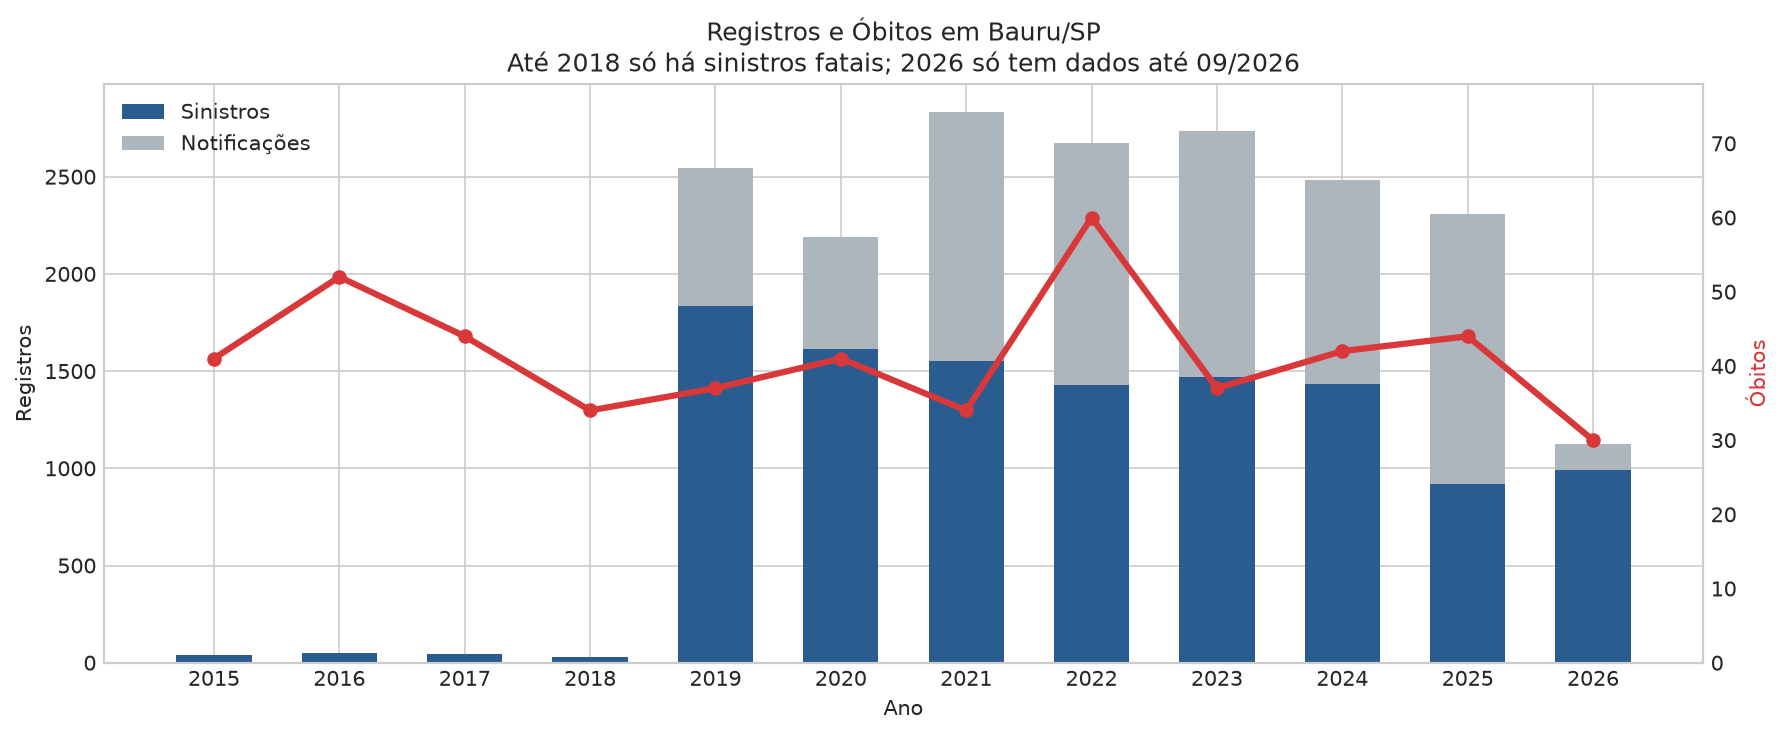

In [2]:
resumo_anual = df.groupby('ano').agg(
    sinistros=('tipo_registro', lambda s: int((s != 'NOTIFICACAO').sum())),
    notificacoes=('tipo_registro', lambda s: int((s == 'NOTIFICACAO').sum())),
    obitos=('obitos', 'sum'),
    feridos_graves=('feridos_graves', 'sum'),
    feridos_leves=('feridos_leves', 'sum')
).reset_index()

display(resumo_anual)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(resumo_anual['ano'], resumo_anual['sinistros'], color='#2b5c8f', width=0.6, label='Sinistros')
ax1.bar(resumo_anual['ano'], resumo_anual['notificacoes'], bottom=resumo_anual['sinistros'], color='#adb5bd', width=0.6, label='Notificações')
ax1.set_xlabel('Ano')
ax1.set_ylabel('Registros')
ax1.set_xticks(resumo_anual['ano'])
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(resumo_anual['ano'], resumo_anual['obitos'], color='#d9383a', linewidth=3, marker='o')
ax2.set_ylabel('Óbitos', color='#d9383a')
ax2.set_ylim(0, resumo_anual['obitos'].max() * 1.3)
ax2.grid(False)

fim = pd.to_datetime(df['data_sinistro_dt']).max()
# O ano do último registro só está completo se os dados chegam a 31/12
aviso_parcial = f"; {fim.year} só tem dados até {fim:%m/%Y}" if (fim + pd.Timedelta(days=1)).year == fim.year else ""
plt.title(f"Registros e Óbitos em Bauru/SP\nAté 2018 só há sinistros fatais{aviso_parcial}")
plt.tight_layout()
plt.show()

## 2. Dias Úteis vs Fins de Semana
Cada dia do calendário conta, inclusive os dias sem nenhum registro. Um p-valor alto não prova que as médias sejam iguais.

In [3]:
teste = comparar_dias(df[df['ano'] >= 2019])
print(f"Média em dias úteis: {teste['media_uteis']:.2f} registros/dia")
print(f"Média em fins de semana: {teste['media_fds']:.2f} registros/dia")
print(f"Diferença: {teste['diferenca']:.2f} (IC95% {teste['ic95'][0]:.2f} a {teste['ic95'][1]:.2f}), p = {teste['p_welch']:.3f}")
print(f"Dias sem registro: {teste['dias_sem_registro_pct']:.1f}%")
print("Média por dia (segunda a domingo):", teste['media_por_dia'].round(2).tolist())

Média em dias úteis: 6.70 registros/dia
Média em fins de semana: 6.63 registros/dia
Diferença: -0.07 (IC95% -0.36 a 0.22), p = 0.634
Dias sem registro: 1.1%
Média por dia (segunda a domingo): [6.2, 6.5, 6.36, 6.68, 7.75, 7.35, 5.9]


## 3. Letalidade na Base Comparável
Letalidade = sinistros com óbito ÷ sinistros do tipo. A base não informa velocidade nem qual objeto foi atingido.

In [4]:
display(tabela_letalidade(comparavel))

for tipo_via, base in comparavel[comparavel['tipo_via'] != 'NAO DISPONIVEL'].groupby('tipo_via'):
    razao, inferior, superior = razao_letalidade(base, 'CHOQUE', 'COLISAO')
    print(f"{tipo_via}: choque/colisão = {razao:.2f} (IC95% {inferior:.2f} a {superior:.2f})")

,tipo_sinistro_simplificado,sinistros,sinistros_fatais,obitos,feridos_graves,letalidade_pct
0,ATROPELAMENTO,722,84,84,106,11.63
1,CHOQUE,1167,68,69,133,5.83
2,OUTROS,2151,58,63,185,2.70
3,COLISAO,7102,103,109,670,1.45
4,OUTROS / NAO INFORMADO,107,0,0,13,0.00


ESTRADAS E RODOVIAS: choque/colisão = 0.93 (IC95% 0.57 a 1.54)
VIAS URBANAS: choque/colisão = 5.94 (IC95% 4.07 a 8.66)


## 4. Matriz de Calor: Horário do Dia vs Dia da Semana
Volume não equivale a risco, pois a base não traz o fluxo de veículos.

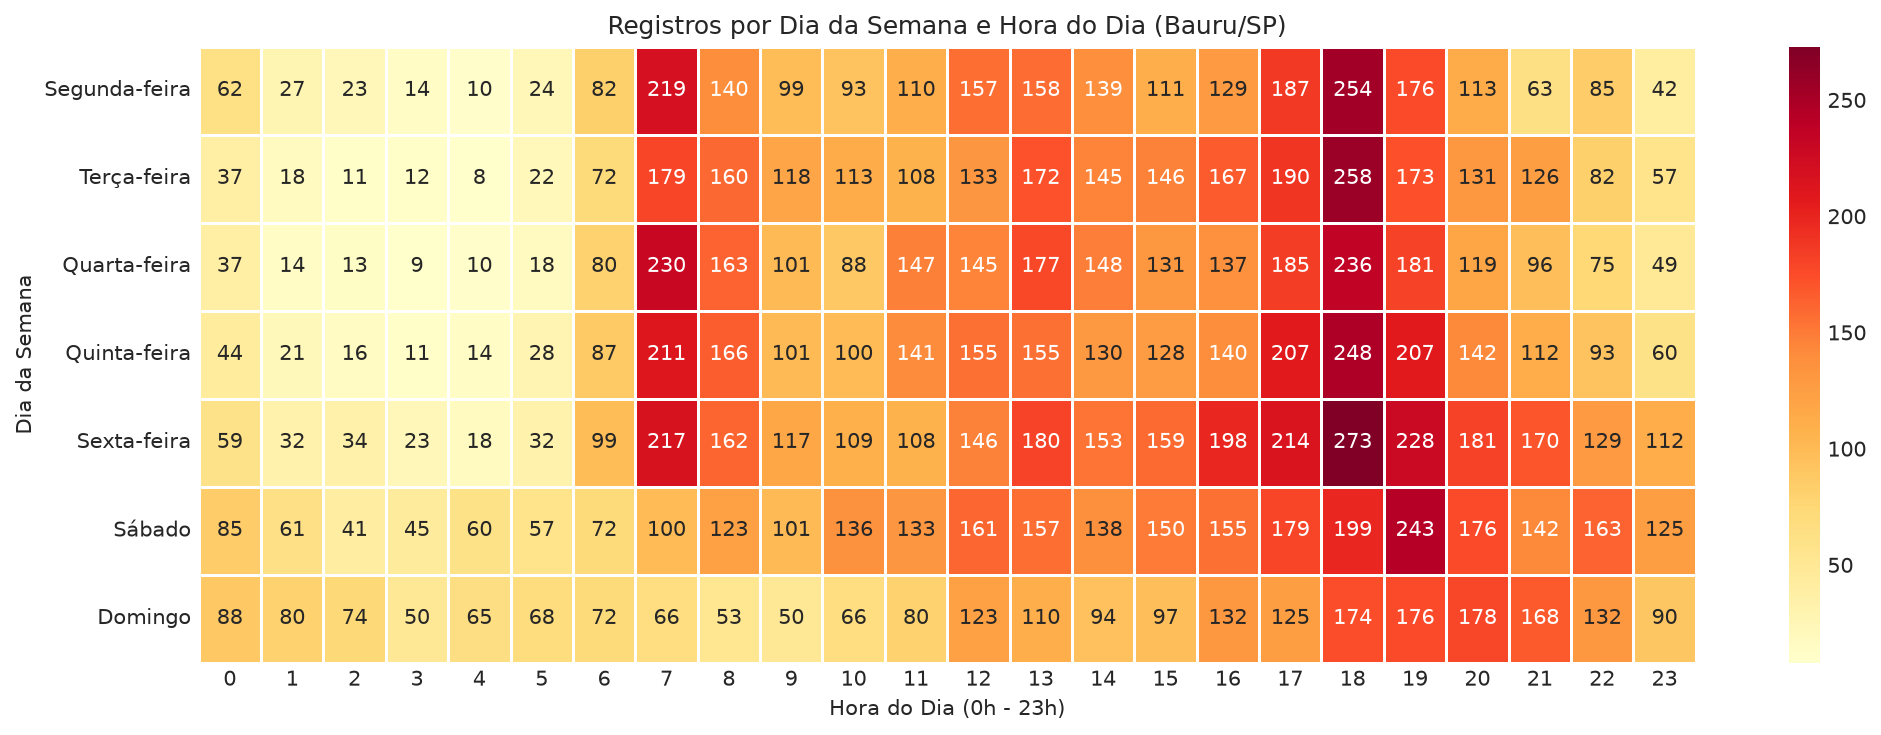

In [5]:
ordem_dias = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira', 'Sábado', 'Domingo']
heatmap_data = df[df['hora_num'].notnull()].pivot_table(
    index='dia_da_semana_limpo',
    columns='hora_num',
    values='id_sinistro',
    aggfunc='count',
    fill_value=0
).reindex(index=ordem_dias, columns=range(24), fill_value=0)

plt.figure(figsize=(14, 5))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt='d', linewidths=0.5)
plt.title('Registros por Dia da Semana e Hora do Dia (Bauru/SP)')
plt.xlabel('Hora do Dia (0h - 23h)')
plt.ylabel('Dia da Semana')
plt.tight_layout()
plt.show()

## 5. Modelo Exploratório (Regressão Logística)
O modelo usa dados conhecidos só depois do sinistro, então não prevê acidentes. As razões de chance são associações ajustadas pelas demais variáveis, não causas.

Acurácia: 0.875 | Sempre prever a classe mais comum: 0.872
Acurácia balanceada: 0.514 | ROC-AUC: 0.696
PR-AUC: 0.270 (acaso: 0.128)

Validação cruzada estratificada repetida (média ± desvio):
                     media  desvio
auc                  0.678   0.019
pr_auc               0.259   0.021
brier_skill          0.057   0.014
sensibilidade        0.558   0.041
precisao             0.215   0.013
acuracia_balanceada  0.629   0.019

Validação por ano (treino com os anos anteriores):
 ano anos_treino  n_teste  prevalencia   auc  pr_auc  sensibilidade  precisao
2022   2019–2021     1338        0.135 0.663   0.303          0.530     0.218
2023   2019–2022     1383        0.123 0.717   0.265          0.635     0.241
2024   2019–2023     1381        0.143 0.689   0.281          0.553     0.233
2025   2019–2024      911        0.138 0.678   0.253          0.611     0.231
2026   2019–2025      980        0.123 0.696   0.281          0.562     0.226

Referências: {'tipo_via_simplificado': 'VI

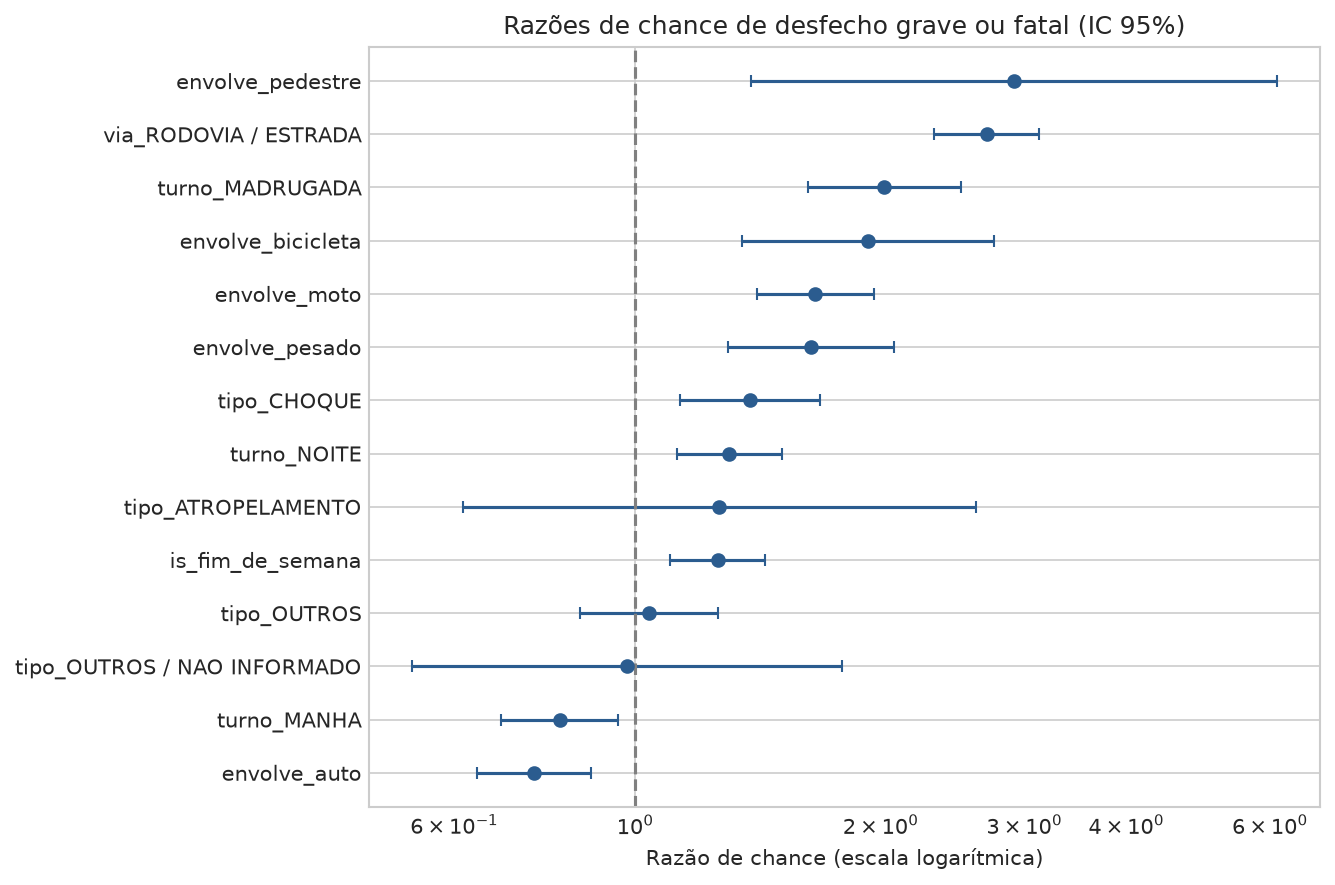

In [6]:
resultado = treinar_modelo(df)
print(f"Acurácia: {resultado['acuracia']:.3f} | Sempre prever a classe mais comum: {resultado['referencia']:.3f}")
print(f"Acurácia balanceada: {resultado['acuracia_balanceada']:.3f} | ROC-AUC: {resultado['auc']:.3f}")
print(f"PR-AUC: {resultado['pr_auc']:.3f} (acaso: {resultado['prevalencia']:.3f})")

print("\nValidação cruzada estratificada repetida (média ± desvio):")
print(resultado['validacao_cruzada'][['media', 'desvio']].round(3))

print("\nValidação por ano (treino com os anos anteriores):")
print(resultado['temporal'][['ano', 'anos_treino', 'n_teste', 'prevalencia', 'auc', 'pr_auc', 'sensibilidade', 'precisao']].round(3).to_string(index=False))

print("\nReferências:", resultado['referencias'])
rc = resultado['razoes_chance']
print(rc.round(3).to_string())

rc = rc.sort_values('razao_chance')
plt.figure(figsize=(9, 6))
plt.errorbar(rc['razao_chance'], range(len(rc)), xerr=[rc['razao_chance'] - rc['ic_inf'], rc['ic_sup'] - rc['razao_chance']], fmt='o', color='#2b5c8f', capsize=3)
plt.axvline(1, color='gray', linestyle='--')
plt.xscale('log')
plt.yticks(range(len(rc)), rc.index)
plt.title('Razões de chance de desfecho grave ou fatal (IC 95%)')
plt.xlabel('Razão de chance (escala logarítmica)')
plt.tight_layout()
plt.show()